
================ ERI ABLATION STUDY (MODEL-WISE) ================

            Model  Accuracy_Stability_Mean  LMOS_Stability_Mean  ERI (Full)  ERI w/o Accuracy  ERI w/o LMOS
       Custom CNN                   0.7864               0.5556     0.67100           0.27780       0.39320
      Densenet121                   0.9665               0.8130     0.88975           0.40650       0.48325
InceptionResnetV2                   0.9552               0.6969     0.82605           0.34845       0.47760
     Inception V3                   0.9544               0.6253     0.78985           0.31265       0.47720
     MobileNet V2                   0.9523               0.7840     0.86815           0.39200       0.47615
         ResNet50                   0.7553               0.8565     0.80590           0.42825       0.37765
            VGG16                   0.9526               0.6988     0.82570           0.34940       0.47630
         Xception                   0.9471               0.8493     

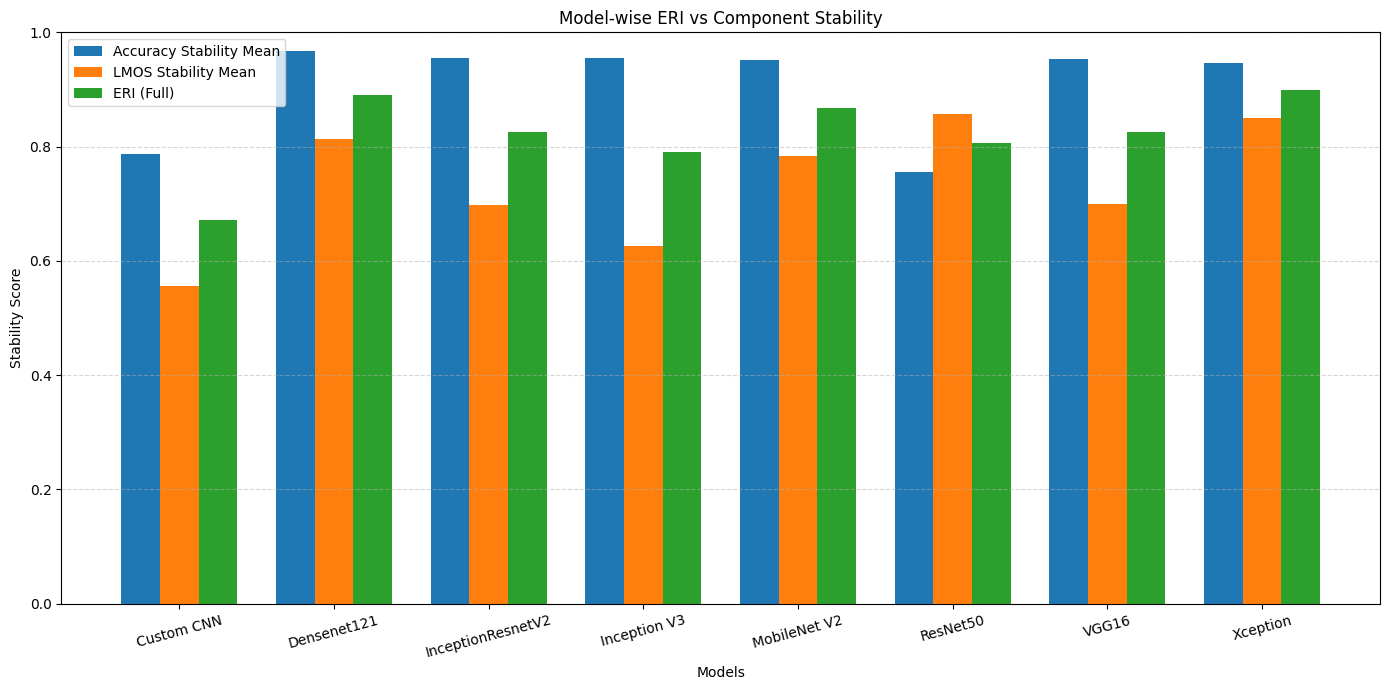

Saved: eri_modelwise_components.png


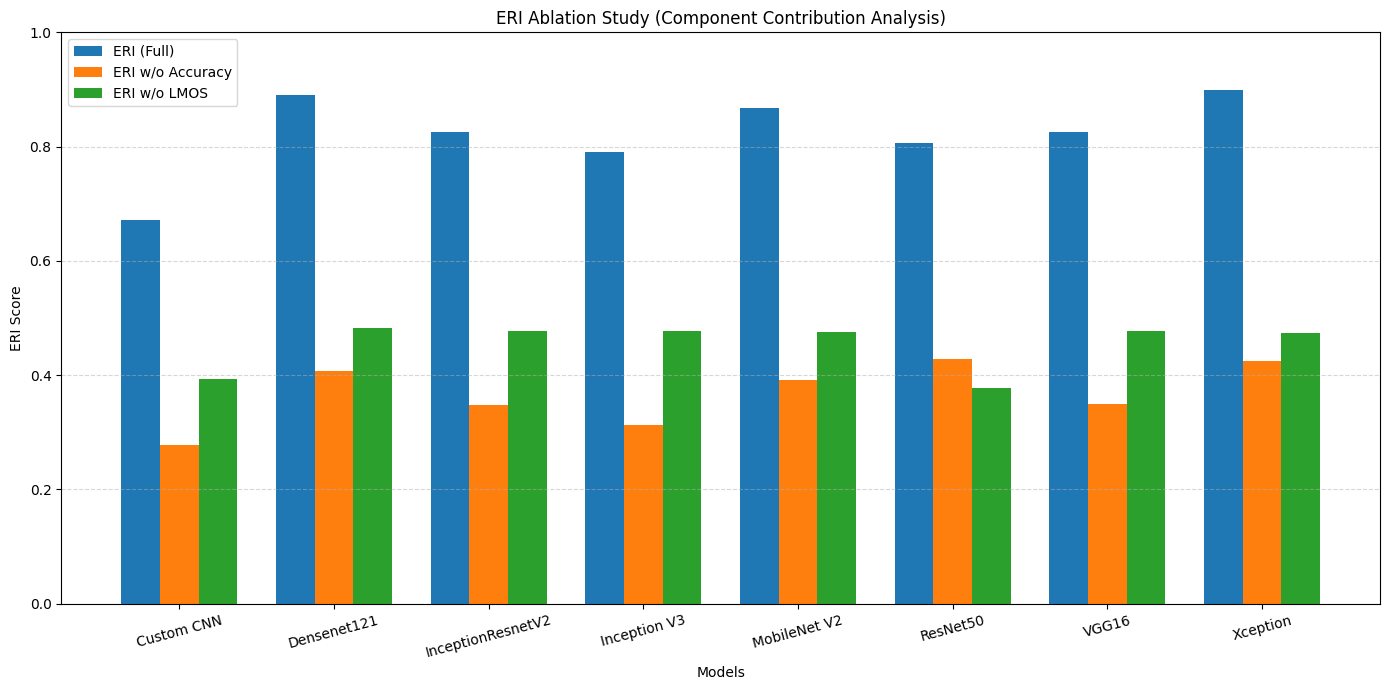

Saved: eri_modelwise_ablation.png
Saved: eri_modelwise_ablation.csv


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================
# MODEL NAMES
# ====================================================

models = [
    "Custom CNN",
    "Densenet121",
    "InceptionResnetV2",
    "Inception V3",
    "MobileNet V2",
    "ResNet50",
    "VGG16",
    "Xception"
    
]



np.random.seed(42)

accuracy_stability_mean = [0.7864, 0.9665, 0.9552, 0.9544, 0.9523, 0.7553, 0.9526, 0.9471]
lmos_stability_mean     = [0.5556, 0.8130, 0.6969, 0.6253, 0.7840, 0.8565, 0.6988, 0.8493]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(accuracy_stability_mean, lmos_stability_mean)]
eri_no_accuracy = [l / 2 for l in lmos_stability_mean]
eri_no_lmos     = [a / 2 for a in accuracy_stability_mean]

# ====================================================
# TABLE WITH ABLATION
# ====================================================

df = pd.DataFrame({
    "Model": models,
    "Accuracy_Stability_Mean": accuracy_stability_mean,
    "LMOS_Stability_Mean": lmos_stability_mean,
    "ERI (Full)": eri_full,
    "ERI w/o Accuracy": eri_no_accuracy,
    "ERI w/o LMOS": eri_no_lmos
})

# ====================================================
# PRINT TABLE
# ====================================================

print("\n================ ERI ABLATION STUDY (MODEL-WISE) ================\n")
print(df.to_string(index=False))

# ====================================================
# PLOT 1: COMPONENT COMPARISON
# ====================================================

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14,7))

plt.bar(x - width, accuracy_stability_mean, width, label="Accuracy Stability Mean")
plt.bar(x, lmos_stability_mean, width, label="LMOS Stability Mean")
plt.bar(x + width, eri_full, width, label="ERI (Full)")

plt.xticks(x, models, rotation=15)
plt.ylabel("Stability Score")
plt.xlabel("Models")
plt.title("Model-wise ERI vs Component Stability")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_components.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_components.png")

# ====================================================
# PLOT 2: ABLATION VISUALIZATION
# ====================================================

plt.figure(figsize=(14,7))

plt.bar(x - width, eri_full, width, label="ERI (Full)")
plt.bar(x, eri_no_accuracy, width, label="ERI w/o Accuracy")
plt.bar(x + width, eri_no_lmos, width, label="ERI w/o LMOS")

plt.xticks(x, models, rotation=15)
plt.ylabel("ERI Score")
plt.xlabel("Models")
plt.title("ERI Ablation Study (Component Contribution Analysis)")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_ablation.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_ablation.png")

# ====================================================
# SAVE TABLE
# ====================================================

df.to_csv("eri_modelwise_ablation.csv", index=False)

print("Saved: eri_modelwise_ablation.csv")